# Mortgage prepayment and delinquency risk

End-to-end walkthrough of the [`mbs_risk`](https://github.com/benisalla/mortgage-prepayment-risk)
package on 291,451 Freddie Mac fixed-rate mortgages (first payments 1999-2013):

1. load and clean the loan export,
2. engineer origination-time features,
3. explore the data and test the original hypotheses H1-H6,
4. model **delinquency** (`EverDelinquent`) and **prepayment within 36 months** (`Prepaid36`),
5. evaluate (ROC-AUC, PR-AUC, tuned-threshold F1, calibration) and explain the models.

Every number below is computed in this notebook; the README quotes the same pipeline.

In [1]:
# Setup: works locally (repo checkout) and on Kaggle / Colab (clones the repo).
import os, subprocess, sys
try:
    import mbs_risk
except ImportError:
    if not os.path.exists("mortgage-prepayment-risk"):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/benisalla/mortgage-prepayment-risk.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "mortgage-prepayment-risk"], check=True)
    sys.path.insert(0, os.path.abspath("mortgage-prepayment-risk/src"))
    import mbs_risk
import pandas as pd
from IPython.display import Image, display
from mbs_risk import config, plotting
pd.set_option("display.width", 160, "display.max_columns", 40)
FIG = config.ROOT / "outputs" / "notebook"
FIG.mkdir(parents=True, exist_ok=True)
def show(fn, *args, name, **kw):
    fn(*args, path=FIG / name, **kw)
    display(Image(filename=str(FIG / name)))
print("mbs_risk", mbs_risk.__version__)

mbs_risk 1.0.0


## 1. Load and clean

`download_data()` fetches the full export (37 MB) into `data/raw/` once; `load_loans()`
reads it. Set `USE_SAMPLE = True` to run everything on the 5,000-row stratified sample
shipped with the repo, in a minute.

In [2]:
USE_SAMPLE = False
raw = mbs_risk.load_loans(config.SAMPLE_CSV if USE_SAMPLE else mbs_risk.download_data())
print(raw.shape)
raw.head()

(291451, 28)


,CreditScore,FirstPaymentDate,FirstTimeHomebuyer,MaturityDate,MSA,MIP,Units,Occupancy,OCLTV,DTI,OrigUPB,LTV,OrigInterestRate,Channel,PPM,ProductType,PropertyState,PropertyType,PostalCode,LoanSeqNum,LoanPurpose,OrigLoanTerm,NumBorrowers,SellerName,ServicerName,EverDelinquent,MonthsDelinquent,MonthsInRepayment
0,0,199902,N,202901,16974,25,1,O,89,27,117000,89,6.750,T,N,FRM,IL,SF,60400,F199Q1268030,P,360,2,FL,WASHINGTONMUTUALBANK,0,0,52
1,0,199902,N,202901,19740,0,1,O,73,17,109000,73,6.500,R,N,FRM,CO,SF,80200,F199Q1015092,N,360,1,FT,CHASEHOMEFINANCELLC,0,0,144
2,0,199902,N,202901,29940,0,1,O,75,16,88000,75,6.875,T,N,FRM,KS,SF,66000,F199Q1266886,N,360,2,FL,WASHINGTONMUTUALBANK,0,0,67
3,0,199902,N,202901,31084,0,1,O,76,14,160000,76,6.875,R,N,FRM,CA,SF,90700,F199Q1178167,N,360,2,GM,GMACMTGECORP,0,0,35
4,0,199902,N,202901,35644,0,1,O,78,18,109000,78,7.125,R,N,FRM,NJ,SF,7600,F199Q1178517,N,360,2,GM,GMACMTGECORP,0,0,54


In [3]:
from mbs_risk.cleaning import missing_report
df = mbs_risk.prepare(raw)          # clean + features + bins + targets
missing_report(df).round(2)

,missing,pct
FirstTimeHomebuyer,78015,26.77
Prepaid36,57663,19.78
MSA,39100,13.42
SellerName,24994,8.58
EstMonthlyIncome,17796,6.11
DTI,17796,6.11
DTI_Range,17796,6.11
PPM,5405,1.85
CreditScore,1189,0.41
CreditRange,1189,0.41


Missing-value codes: `"X"` in code columns (MSA, first-time buyer, PPM, number of
borrowers), and impossible zeros (credit score, LTV, DTI). They become real missing values;
the model pipeline imputes them (median / constant) and adds missing-indicator columns.

## 2. Targets and leakage

* `EverDelinquent` is given. `MonthsDelinquent > 0` is *exactly* `EverDelinquent == 1`, so it is
  dropped from the inputs (the original notebook kept it, which makes the task trivial).
* `MonthsInRepayment` is the observed life of the loan, known only after the fact; it defines the
  prepayment target and is never a model input.
* `Prepaid36 = 1` when a never-delinquent loan left the pool within 36 months of its first
  payment (voluntary payoff: refinance or sale). Ever-delinquent loans are excluded from this
  task, because an early exit after delinquency may be a default.

In [4]:
from mbs_risk.features import model_frame
for t in [config.DELINQ_TARGET, config.PREPAY_TARGET]:
    X, y = model_frame(df, t)
    print(f"{t:15s} rows={len(y):,} positive rate={y.mean():.3f} inputs={X.shape[1]}")
pd.crosstab(df.EverDelinquent, df.MonthsDelinquent > 0)

EverDelinquent  rows=291,451 positive rate=0.198 inputs=24
Prepaid36       rows=233,788 positive rate=0.305 inputs=24


MonthsDelinquent,False,True
EverDelinquent,,
0,233788,0
1,0,57663


## 3. Exploratory analysis

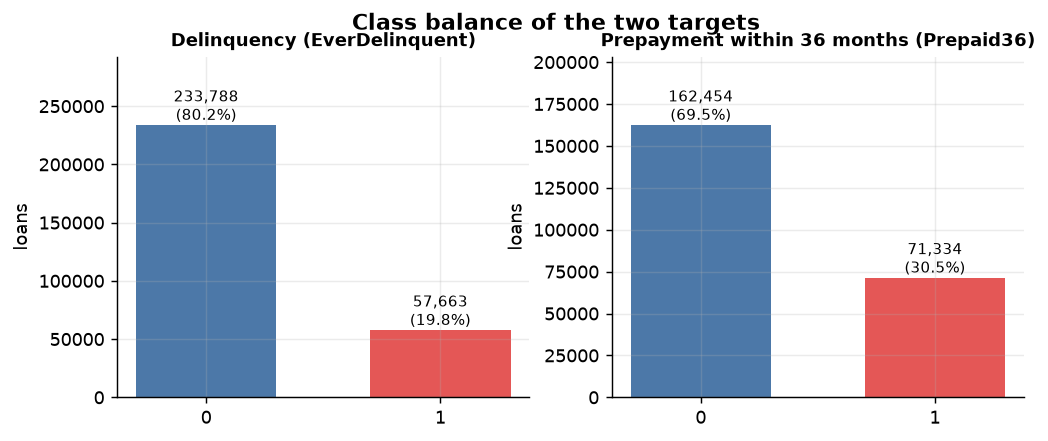

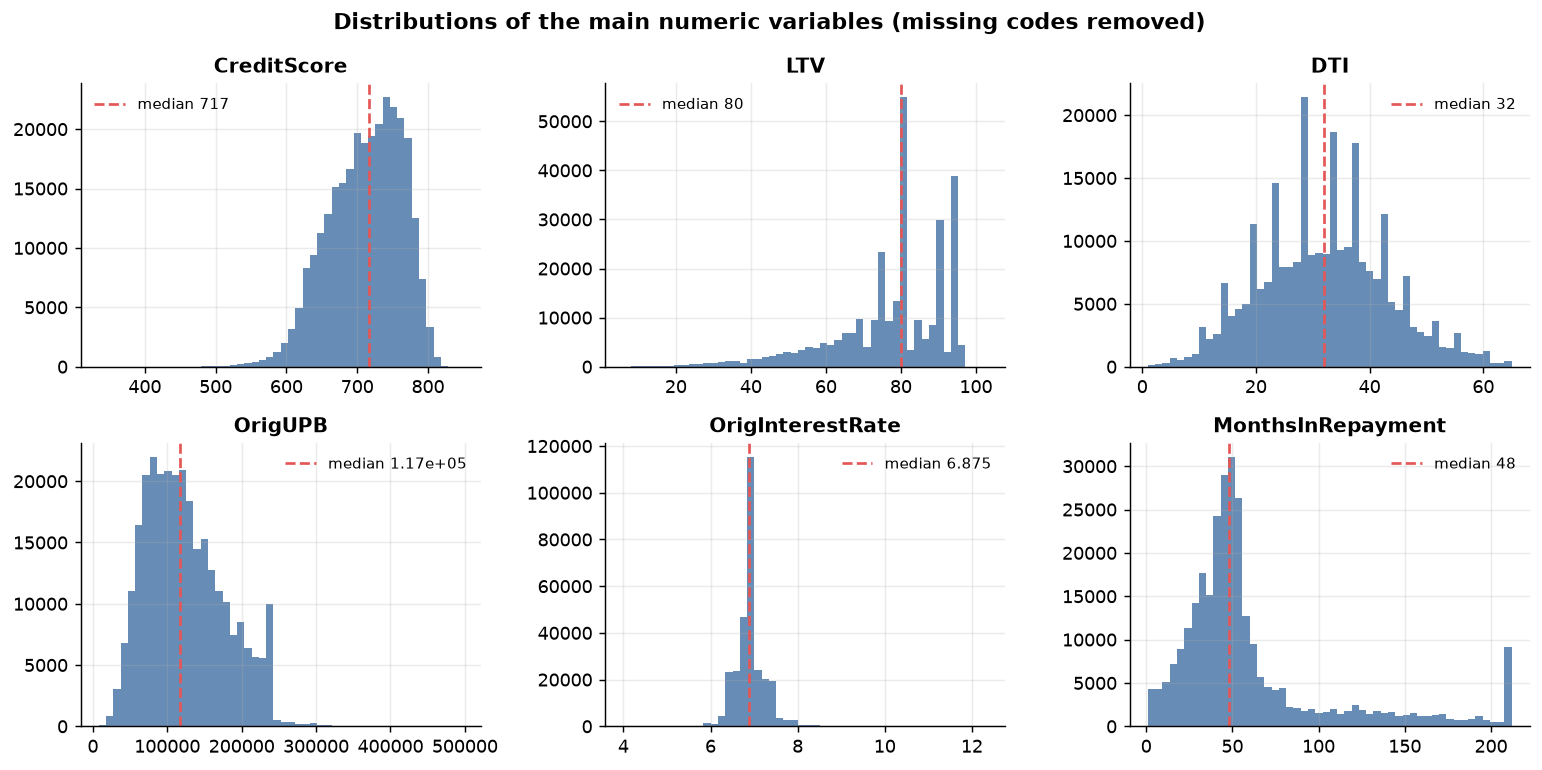

In [5]:
show(plotting.plot_target_balance, df, name="target_balance.png")
show(plotting.plot_distributions, df, name="distributions.png")

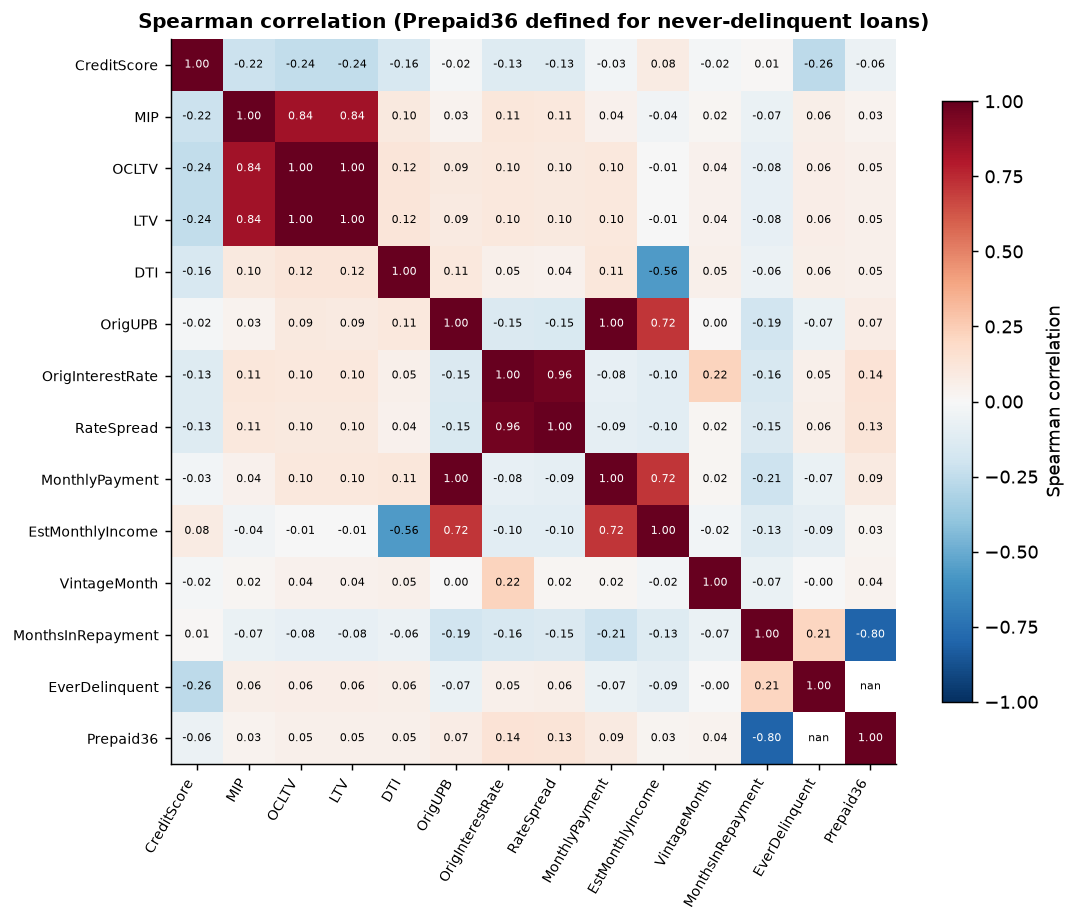

In [6]:
show(plotting.plot_correlation, df, name="correlation.png")

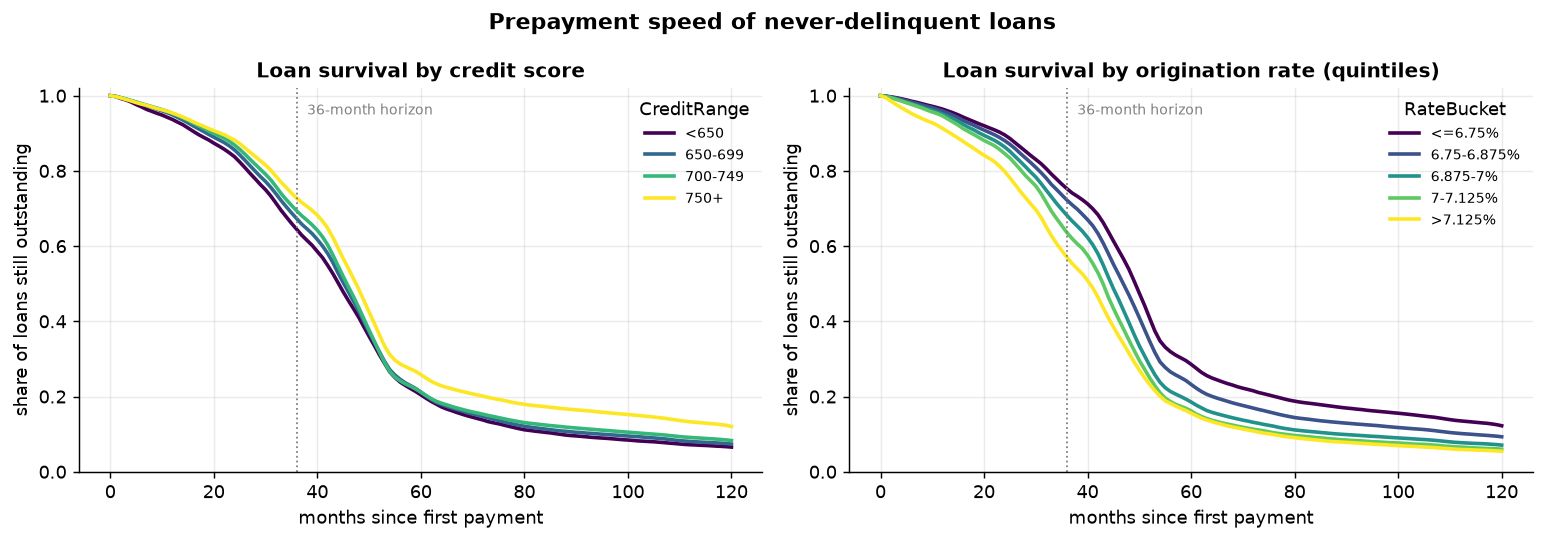

In [7]:
show(plotting.plot_survival, df, name="survival.png")

## 4. Hypotheses H1-H6

All six original hypotheses are about prepayment, so they are tested with `Prepaid36` on
never-delinquent loans. Verdicts are based on effect size (at least 2 percentage points between
the extreme groups); with ~230k loans every p-value is tiny.

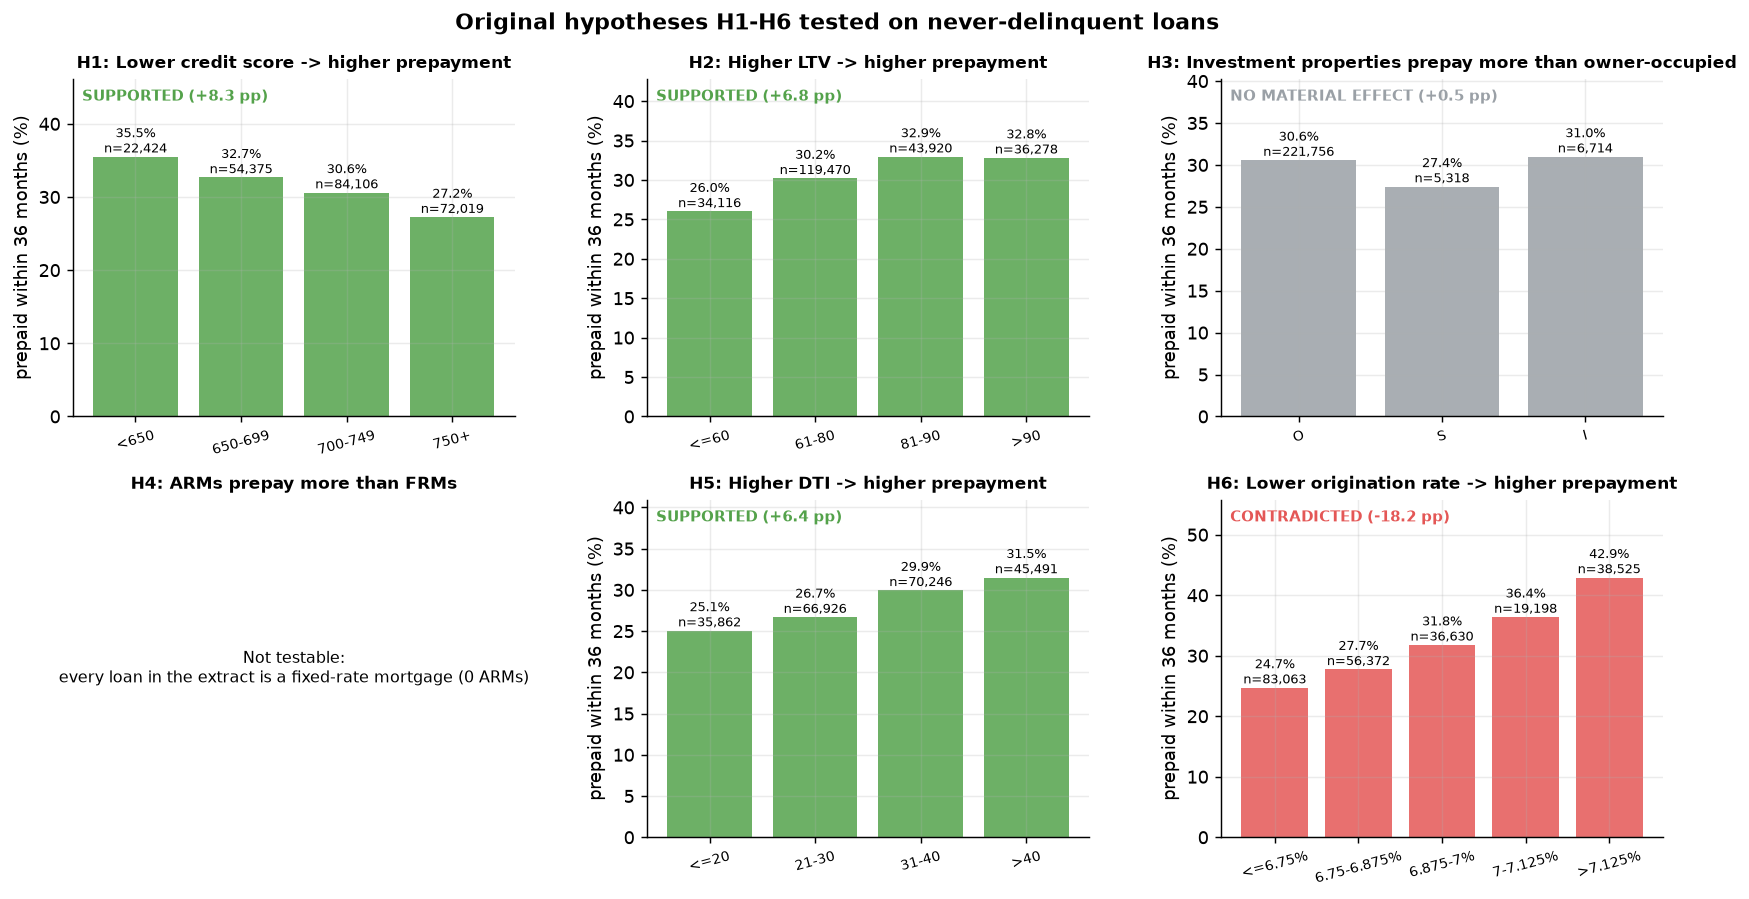

,statement,verdict,detail,effect_pp,p_value,spearman
key,,,,,,
H1,Lower credit score -> higher prepayment,supported,<650: 35.5% -> 750+: 27.2%,8.269343,1.038250e-161,-0.056088
H2,Higher LTV -> higher prepayment,supported,<=60: 26.0% -> >90: 32.8%,6.793925,1.146656e-117,0.045699
H3,Investment properties prepay more than owner-o...,no material effect,I: 31.0% vs others 30.5%,0.481614,3.524857e-06,NaN
H4,ARMs prepay more than FRMs,not testable,every loan in the extract is a fixed-rate mort...,NaN,NaN,NaN
H5,Higher DTI -> higher prepayment,supported,<=20: 25.1% -> >40: 31.5%,6.446952,2.303179e-127,0.051534
H6,Lower origination rate -> higher prepayment,contradicted,<=6.75%: 24.7% -> >7.125%: 42.9%,-18.211602,0.000000e+00,0.133349


In [8]:
hyp = mbs_risk.check_hypotheses(df)
show(plotting.plot_hypotheses, hyp, name="hypotheses.png")
hyp.drop(columns="rates")

## 5. Delinquency model (`EverDelinquent`)

Stratified 64/16/20 train/validation/test split. Each model is a single scikit-learn pipeline
(impute, one-hot, cross-fitted target encoding for state/MSA/seller), so no statistic is fitted
on validation or test rows. The F1 threshold is tuned on validation.

In [9]:
MODELS = ["majority", "logreg", "hist_gb", "xgboost"]   # random_forest is in scripts/train.py
deq = mbs_risk.run_task(df, config.DELINQ_TARGET, MODELS)
deq.metrics.round(4)

[EverDelinquent] majority       roc_auc=0.5000 pr_auc=0.1979 f1=0.0000 (2s)


[EverDelinquent] logreg         roc_auc=0.7131 pr_auc=0.3736 f1=0.4359 (4s)


[EverDelinquent] hist_gb        roc_auc=0.7169 pr_auc=0.3792 f1=0.4388 (13s)


[EverDelinquent] xgboost        roc_auc=0.7153 pr_auc=0.3795 f1=0.4352 (13s)


,roc_auc,pr_auc,prevalence,brier,threshold,f1,precision,recall,accuracy,tn,fp,fn,tp,fit_seconds
model,,,,,,,,,,,,,,
majority,0.5000,0.1979,0.1979,0.1587,0.5000,0.0000,0.0000,0.0000,0.8021,46758,0,11533,0,2.1430
logreg,0.7131,0.3736,0.1979,0.1438,0.2147,0.4359,0.3393,0.6093,0.6880,33077,13681,4506,7027,4.0289
hist_gb,0.7169,0.3792,0.1979,0.1430,0.2151,0.4388,0.3433,0.6078,0.6924,33350,13408,4523,7010,12.8943
xgboost,0.7153,0.3795,0.1979,0.1432,0.2139,0.4352,0.3378,0.6114,0.6860,32938,13820,4482,7051,12.8112


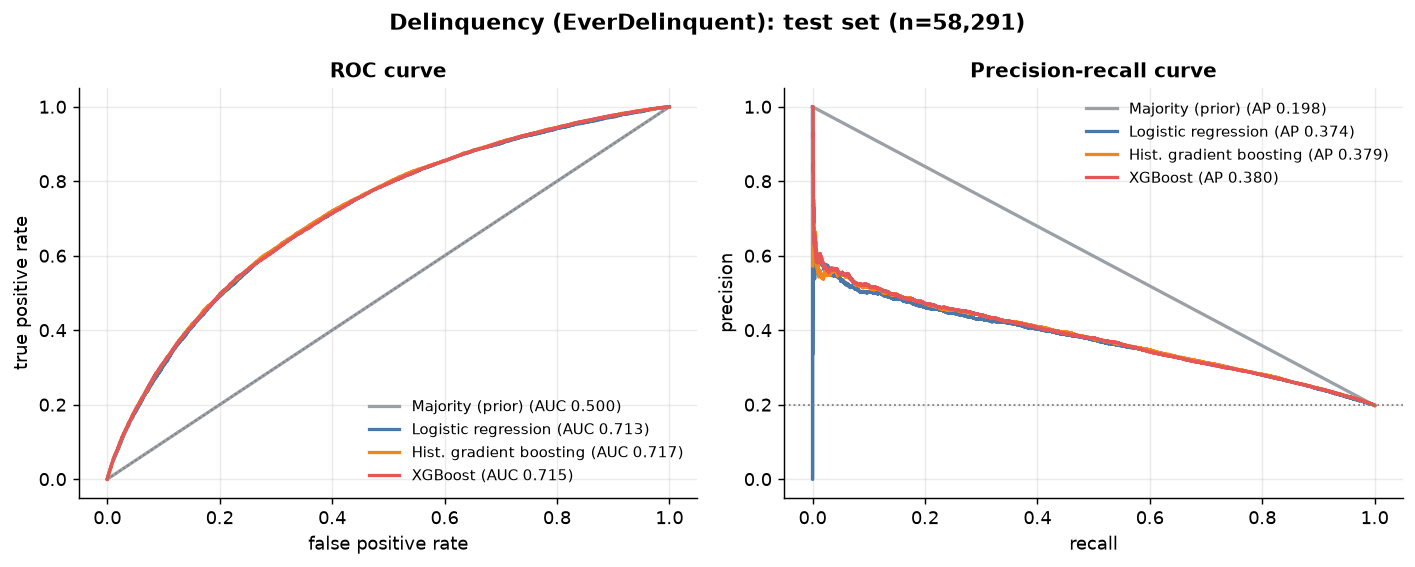

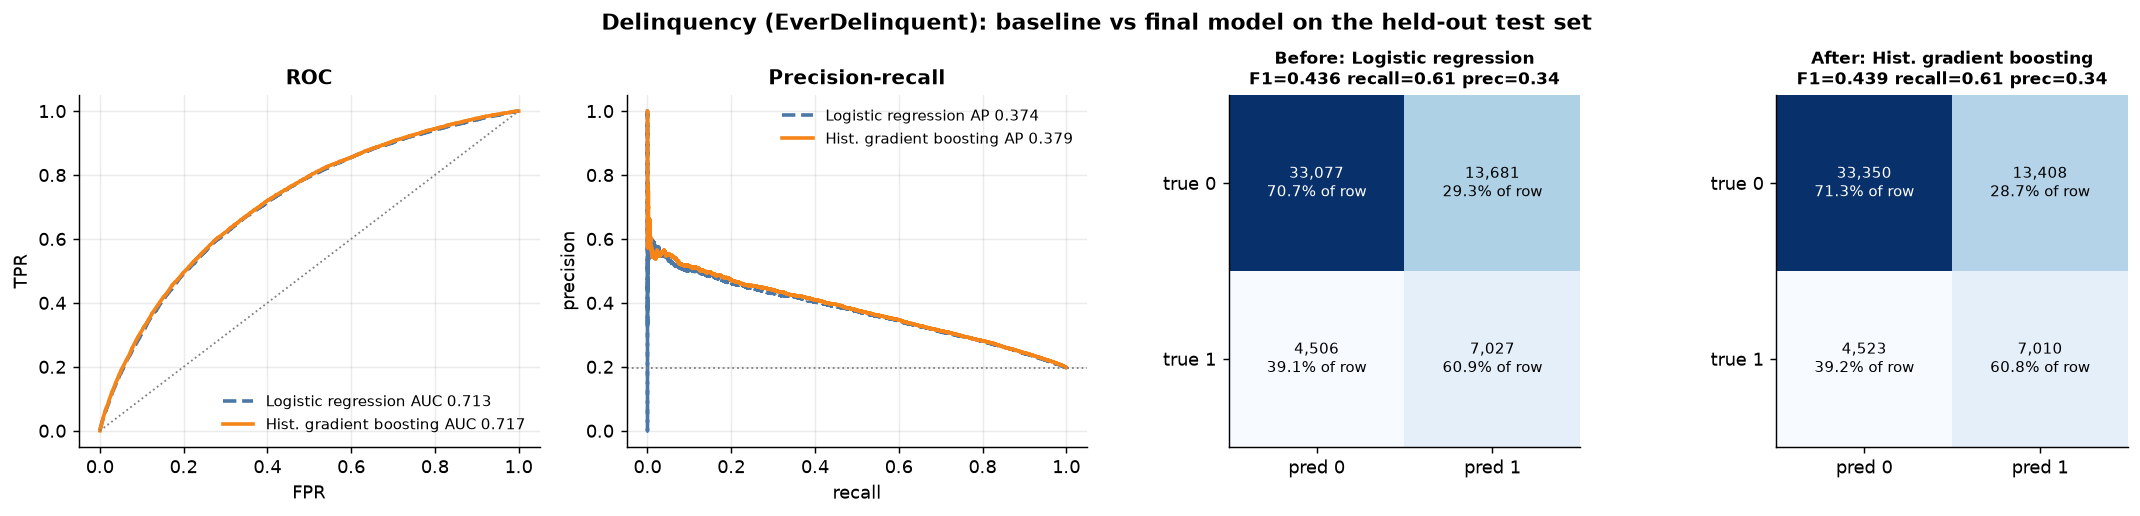

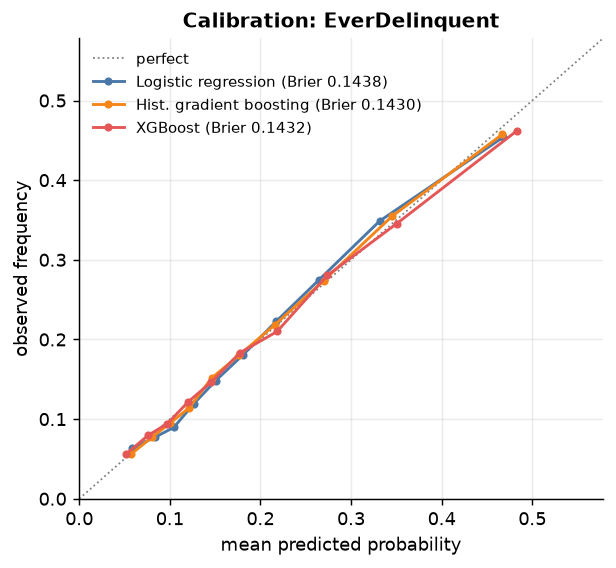

In [10]:
show(plotting.plot_roc_pr, deq, name="roc_pr_delinq.png")
show(plotting.plot_before_after, deq, "logreg", deq.best_model(), name="before_after_delinq.png")
show(plotting.plot_calibration, deq, name="calibration_delinq.png")

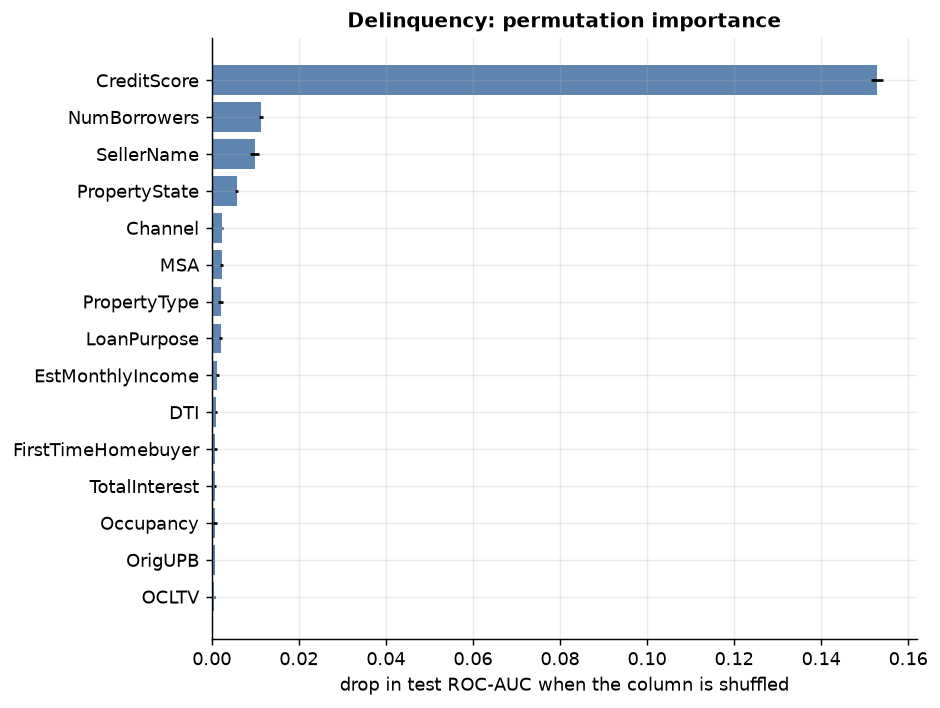

,feature,importance,std
0,CreditScore,0.1529,0.0014
1,NumBorrowers,0.0112,0.0005
2,SellerName,0.0099,0.0010
3,PropertyState,0.0057,0.0004
4,Channel,0.0024,0.0001
5,MSA,0.0023,0.0003
6,PropertyType,0.0020,0.0006
7,LoanPurpose,0.0020,0.0004
8,EstMonthlyIncome,0.0013,0.0003
9,DTI,0.0009,0.0002


In [11]:
from mbs_risk.evaluation import permutation_importance_table
imp_deq = permutation_importance_table(deq.models[deq.best_model()], deq.X_test, deq.y_test)
show(plotting.plot_importance, imp_deq, "Delinquency: permutation importance", name="importance_delinq.png")
imp_deq.head(10).round(4)

## 6. Prepayment model (`Prepaid36`)

In [12]:
pre = mbs_risk.run_task(df, config.PREPAY_TARGET, MODELS)
pre.metrics.round(4)

[Prepaid36] majority       roc_auc=0.5000 pr_auc=0.3051 f1=0.0000 (2s)


[Prepaid36] logreg         roc_auc=0.6787 pr_auc=0.5170 f1=0.5052 (3s)


[Prepaid36] hist_gb        roc_auc=0.6997 pr_auc=0.5506 f1=0.5187 (12s)


[Prepaid36] xgboost        roc_auc=0.6975 pr_auc=0.5500 f1=0.5195 (9s)


,roc_auc,pr_auc,prevalence,brier,threshold,f1,precision,recall,accuracy,tn,fp,fn,tp,fit_seconds
model,,,,,,,,,,,,,,
majority,0.5000,0.3051,0.3051,0.2120,0.5000,0.0000,0.0000,0.0000,0.6949,32491,0,14267,0,1.6957
logreg,0.6787,0.5170,0.3051,0.1902,0.2813,0.5052,0.4227,0.6278,0.6248,20259,12232,5310,8957,2.7998
hist_gb,0.6997,0.5506,0.3051,0.1842,0.2759,0.5187,0.4432,0.6253,0.6460,21284,11207,5346,8921,11.6416
xgboost,0.6975,0.5500,0.3051,0.1846,0.2666,0.5195,0.4325,0.6501,0.6330,20323,12168,4992,9275,9.4340


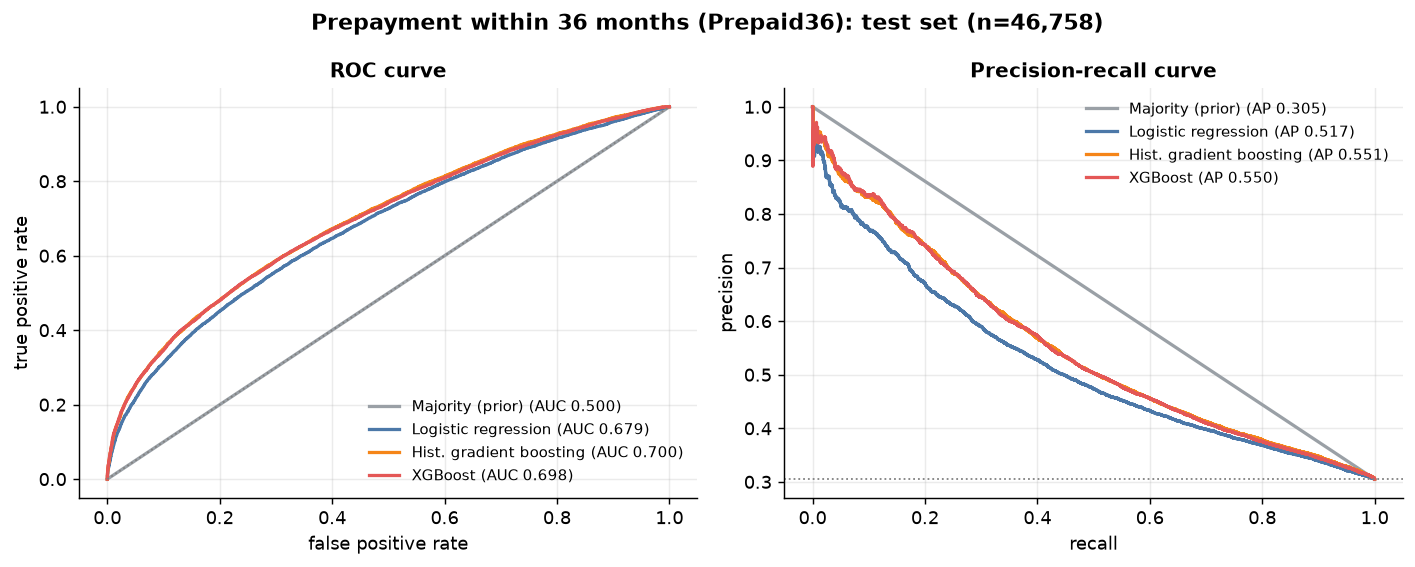

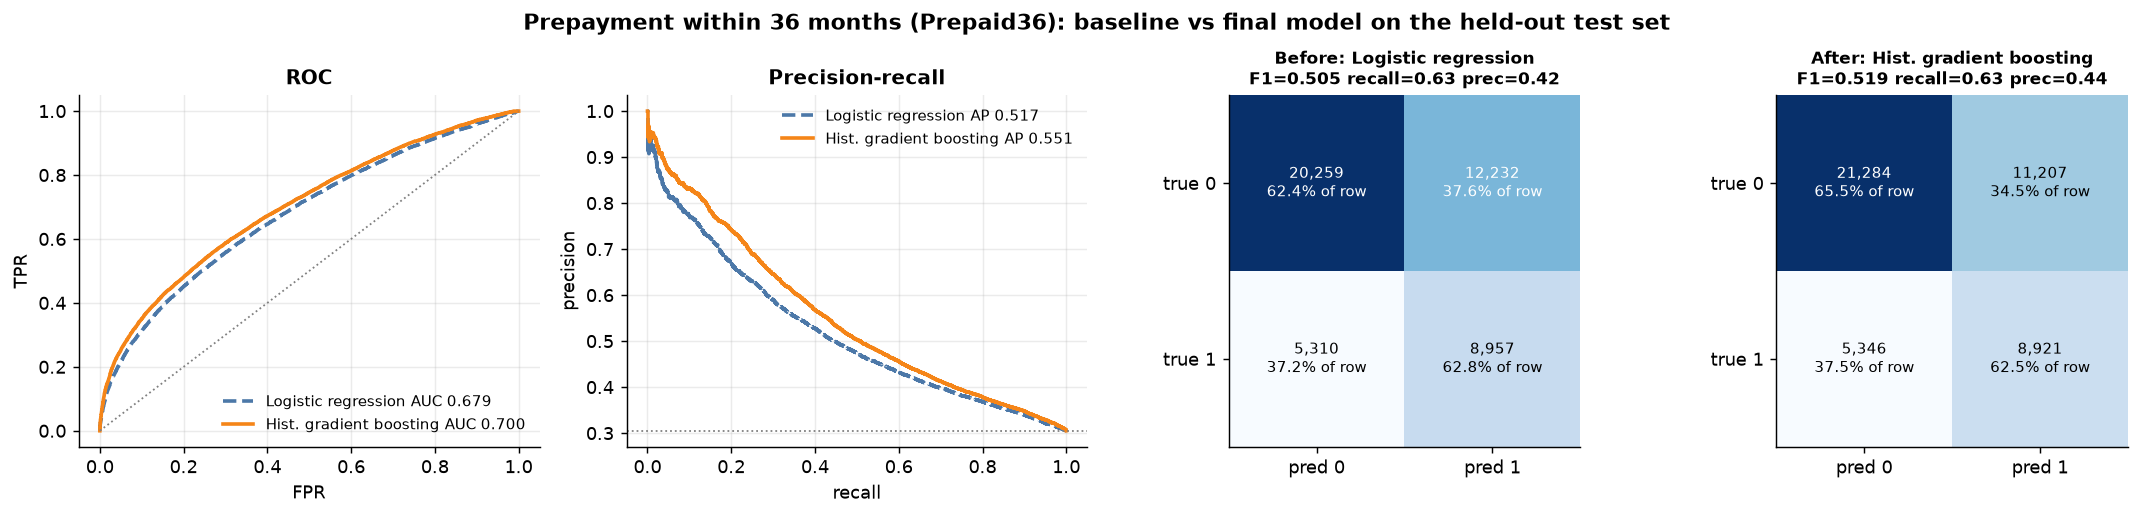

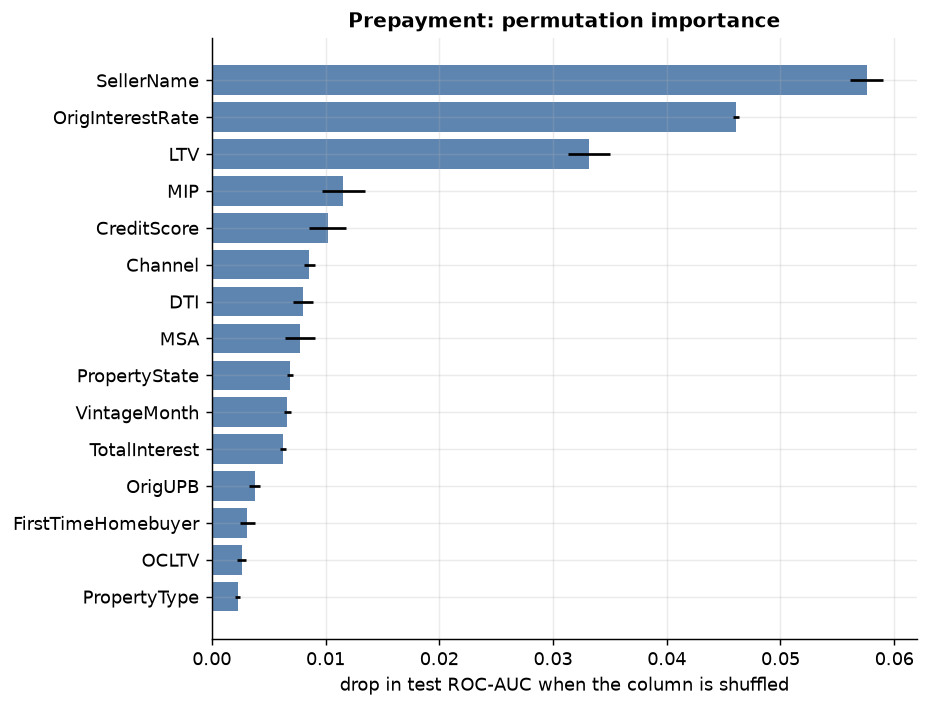

,feature,importance,std
0,SellerName,0.0576,0.0015
1,OrigInterestRate,0.0461,0.0003
2,LTV,0.0332,0.0018
3,MIP,0.0115,0.0019
4,CreditScore,0.0102,0.0016
5,Channel,0.0086,0.0005
6,DTI,0.0080,0.0008
7,MSA,0.0078,0.0013
8,PropertyState,0.0069,0.0002
9,VintageMonth,0.0066,0.0003


In [13]:
show(plotting.plot_roc_pr, pre, name="roc_pr_prepay.png")
show(plotting.plot_before_after, pre, "logreg", pre.best_model(), name="before_after_prepay.png")
imp_pre = permutation_importance_table(pre.models[pre.best_model()], pre.X_test, pre.y_test)
show(plotting.plot_importance, imp_pre, "Prepayment: permutation importance", name="importance_prepay.png")
imp_pre.head(10).round(4)

## 7. Take-aways

* Both targets are only moderately predictable from origination data (test ROC-AUC about 0.72
  for delinquency and 0.70 for prepayment): what happens after origination (market rates,
  house prices, unemployment) drives most of the outcome.
* Gradient boosting beats logistic regression clearly on prepayment (non-linear seller and rate
  effects) and only marginally on delinquency, where credit score dominates.
* The interest rate, LTV and the seller drive prepayment; higher-rate loans prepay much faster,
  which contradicts H6 as written and matches refinance-incentive theory.
* See the README and `docs/results.md` for the full-data numbers and the hypothesis verdicts.